# Data Preparation

**House Demand Forecasting**

## 1 Bibliotheken und Eingabedateien



In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from IPython.display import display

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_DIR / "daten"
OUTPUT_DIR = PROJECT_DIR / "ergebnisse" / "data_preparation"

SOURCES = {
    "dom": {"file": "MEDDAYONMAR53033.csv", "date": "observation_date", "value": "MEDDAYONMAR53033"},
    "pending": {"file": "PENLISCOU53033.csv", "date": "observation_date", "value": "PENLISCOU53033"},
    "active": {"file": "ACTLISCOU53033.csv", "date": "observation_date", "value": "ACTLISCOU53033"},
    "mortgage": {"file": "MORTGAGE30US.csv", "date": "observation_date", "value": "MORTGAGE30US"},
    "permits": {"file": "Building_Permits_Seattle_2016_2026.csv", "date": None, "value": None},
}
# Die vier Kategorien genehmigter Wohneinheiten gemäß Quelldatei eintragen.
PERMIT_CATEGORY_COLUMNS = None
CSV_OPTIONS = {name: {"sep": ","} for name in SOURCES}
START_MONTH, END_MONTH = pd.Period("2017-09", "M"), pd.Period("2026-08", "M")
EDA_CUTOFF = pd.Period("2023-07", "M")
VALIDATION_ORIGINS = pd.period_range("2023-08", "2024-07", freq="M")
TEST_ORIGIN = pd.Period("2025-08", "M")

# Arbeitsannahmen getrennt von den Lag-Längen.

RELEASE_DELAY = {"dom": 2, "pending": 2, "active": 2, "mortgage": 0, "permits": 2}
TARGET_DELAY = 2
LAGS = {"dom": [2, 3, 12], "pending": [2, 12], "active": [3], "mortgage": [2], "permits": [2]}
LAG_COLUMNS = [f"{name}_lag_{lag}" for name, lags in LAGS.items() for lag in lags]
FEATURE_COLUMNS = LAG_COLUMNS + ["month_sin", "month_cos"]
TARGET_COLUMNS = ["target_dom", "target_pending"]

## 2. Daten einlesen und Qualität prüfen

Die fünf Datenquellen werden eingelesen. Datumsspalten werden in Datumswerte und Messwertspalten in Zahlen umgewandelt. Eine Übersicht zeigt die Anzahl der Beobachtungen sowie fehlende und auffällige Werte.

Für die Baugenehmigungen wird zusätzlich geprüft, ob die vier Wohneinheitenkategorien vollständig, nicht negativ und zusammen gleich der angegebenen Gesamtzahl sind. Die Prüfungen erkennen mögliche Datenprobleme; sie entfernen oder ersetzen keine Werte automatisch.

In [ ]:

RAW_DIR = Path(
    r"C:\Users\mmatavela\Desktop\House_Demand_Forecasting\daten"
)

if not RAW_DIR.is_dir():
    raise FileNotFoundError(f"Datenordner nicht gefunden: {RAW_DIR}")

for source_name, source_spec in SOURCES.items():
    file_path = RAW_DIR / source_spec["file"]
    status = "OK" if file_path.is_file() else "FEHLT"
    print(f"{source_name}: {status} – {file_path.name}")
    raw_tables = {}
    SOURCES["permits"]["date"] = "observation_date"
SOURCES["permits"]["value"] = "authorized_units_total"
PERMIT_CATEGORY_COLUMNS = [
    "authorized_units_1_unit",
    "authorized_units_2_units",
    "authorized_units_3_4_units",
    "authorized_units_5plus_units",
]
quality_rows = []
series = {}
for name, spec in SOURCES.items():
    raw = pd.read_csv(RAW_DIR / spec["file"], na_values=["."], **CSV_OPTIONS[name])
    raw_tables[name] = raw.copy()
    if spec["date"] is None or spec["value"] is None:
        raise ValueError(f"Spaltenzuordnung für {name} ergänzen. Vorhandene Spalten: {raw.columns.tolist()}")
    dates = pd.to_datetime(raw[spec["date"]], errors="raise")
    values = pd.to_numeric(raw[spec["value"]], errors="raise")
    quality_rows.append({
        "series": name, "rows": len(raw), "missing": int(values.isna().sum()),
        "zeros": int(values.eq(0).sum()), "date_duplicates": int(dates.duplicated().sum()),
        "negative": int(values.lt(0).sum()), "infinite": int(np.isinf(values).sum()),
    })
    assert dates.notna().all(), f"Fehlendes Datum: {name}"
    assert not dates.duplicated().any(), f"Datumsduplikate: {name}"
    assert not values.lt(0).any() and not np.isinf(values).any(), name
    series[name] = pd.Series(values.to_numpy(), index=pd.DatetimeIndex(dates), name=name).sort_index()
quality_report = pd.DataFrame(quality_rows).set_index("series")
display(quality_report)

if PERMIT_CATEGORY_COLUMNS is None or len(PERMIT_CATEGORY_COLUMNS) != 4:
    raise ValueError("Die vier Wohneinheitenkategorien aus der Genehmigungsdatei zuordnen.")
permit_categories = raw_tables["permits"][PERMIT_CATEGORY_COLUMNS].apply(pd.to_numeric, errors="raise")
permit_total = pd.to_numeric(raw_tables["permits"][SOURCES["permits"]["value"]], errors="raise")
assert permit_categories.notna().all().all()
assert np.isfinite(permit_categories.to_numpy()).all() and permit_categories.ge(0).all().all()
assert np.allclose(permit_categories.sum(axis=1), permit_total)

dom: OK – MEDDAYONMAR53033.csv
pending: OK – PENLISCOU53033.csv
active: OK – ACTLISCOU53033.csv
mortgage: OK – MORTGAGE30US.csv
permits: OK – Building_Permits_Seattle_2016_2026.csv


,rows,missing,zeros,date_duplicates,negative,infinite
series,,,,,,
dom,123,0,0,0,0,0
pending,118,1,2,0,0,0
active,123,0,0,0,0,0
mortgage,2897,0,0,0,0,0
permits,128,0,0,0,0,0


## 3. Gemeinsame monatliche Datenbasis erstellen

Die Datenreihen werden auf einen gemeinsamen Monatsindex von September 2017 bis August 2026 ausgerichtet. Die wöchentlichen Hypothekenzinsen werden durch ihren Mittelwert je Monat zusammengefasst. Bereits monatliche Daten behalten ihre zeitliche Auflösung.

Anschließend werden die fünf Reihen zu einer Tabelle zusammengeführt. Prüfungen stellen sicher, dass der gewählte Zeitraum vollständig ist und keine fehlenden oder unendlichen Messwerte enthält.

In [ ]:
monthly_series = {}
for name in ("dom", "pending", "active", "permits"):
    item = series[name].copy()
    item.index = item.index.to_period("M")
    assert not item.index.duplicated().any(), f"Mehrere Monatswerte: {name}"
    monthly_series[name] = item

weekly_rates = series["mortgage"].loc[
    (series["mortgage"].index.to_period("M") >= START_MONTH)
    & (series["mortgage"].index.to_period("M") <= END_MONTH)
]
assert weekly_rates.notna().all()
monthly_series["mortgage"] = weekly_rates.groupby(weekly_rates.index.to_period("M")).mean()
weekly_counts = weekly_rates.groupby(weekly_rates.index.to_period("M")).size()
month_index = pd.period_range(START_MONTH, END_MONTH, freq="M", name="month")
monthly_base = pd.DataFrame(monthly_series).reindex(month_index)
monthly_base = monthly_base[["dom", "pending", "active", "mortgage", "permits"]]
assert monthly_base.shape == (108, 5)
assert monthly_base.index.is_unique
assert np.isfinite(monthly_base.to_numpy()).all()
assert monthly_base.ge(0).all().all()
assert len(weekly_rates) == 469
assert weekly_counts.value_counts().to_dict() == {4: 71, 5: 37}
# Kontrollwerte aus Tabelle A.2 der Dokumentation.
np.testing.assert_allclose(monthly_base.loc["2017-09"].to_numpy(), [29, 2453, 2849, 3.805, 2066])
display(monthly_base.head(3))
display(monthly_base.tail(3))

,dom,pending,active,mortgage,permits
month,,,,,
2017-09,29.0,2453.0,2849.0,3.805,2066.0
2017-10,31.0,2503.0,2741.0,3.895,2807.0
2017-11,38.0,2328.0,2211.0,3.922,2909.0


,dom,pending,active,mortgage,permits
month,,,,,
2026-06,37.0,2289.0,6913.0,6.4900,1947.0
2026-07,44.0,2013.0,7172.0,6.5420,1702.0
2026-08,45.0,1969.0,7366.0,6.6675,990.0


## 4. Zeitliche Merkmale und zukünftige Zielwerte bilden

Aus den Messwerten werden verzögerte Merkmale (Lag-Features) erstellt. Ein Lag von zwei Monaten verwendet beispielsweise den Wert aus t−2 für den Prognoseursprung t.

Für jeden Prognosehorizont von einem bis zwölf Monaten werden die Merkmale den zukünftigen Zielwerten DOM und Pending Listings aus t+h zugeordnet. Sinus und Kosinus bilden den Kalendermonat des Zielwertes zyklisch ab.

Zeilen ohne vollständige Merkmale oder Zielwerte werden ausgeschlossen. Solche Lücken entstehen insbesondere am Anfang durch die Lags und am Ende durch noch nicht vorhandene zukünftige Zielwerte.

In [4]:
lag_features = pd.DataFrame(index=monthly_base.index)
for name, lags in LAGS.items():
    for lag in lags:
        assert lag >= RELEASE_DELAY[name], f"Lag verletzt Verfügbarkeit: {name}"
        lag_features[f"{name}_lag_{lag}"] = monthly_base[name].shift(lag)

supervised_tables = {}
for horizon in range(1, 13):
    table = lag_features.copy()
    table["origin_month"] = table.index
    table["target_month"] = table.index + horizon
    target_numbers = table["target_month"].dt.month
    table["month_sin"] = np.sin(2 * np.pi * target_numbers / 12)
    table["month_cos"] = np.cos(2 * np.pi * target_numbers / 12)
    table["target_dom"] = monthly_base["dom"].shift(-horizon)
    table["target_pending"] = monthly_base["pending"].shift(-horizon)
    table["target_available_month_assumed"] = table["target_month"] + TARGET_DELAY
    table = table.dropna(subset=FEATURE_COLUMNS + TARGET_COLUMNS).reset_index(drop=True)
    assert len(table) == 108 - 12 - horizon
    assert (table["target_month"] == table["origin_month"] + horizon).all()
    assert np.isfinite(table[FEATURE_COLUMNS + TARGET_COLUMNS].to_numpy()).all()
    supervised_tables[horizon] = table

# Kontrollbeispiel aus Teil A.3.2: Ursprung 08/2023, Horizont 3.
example = supervised_tables[3].set_index("origin_month").loc[pd.Period("2023-08", "M")]
assert example["target_month"] == pd.Period("2023-11", "M")
np.testing.assert_allclose(example[["dom_lag_2", "active_lag_3", "target_dom", "target_pending"]].to_numpy(dtype=float), [30, 2147, 47, 1904])
display(example)

dom_lag_2                             30.0
dom_lag_3                             29.0
dom_lag_12                            33.0
pending_lag_2                       2186.0
pending_lag_12                      2490.0
active_lag_3                        2147.0
mortgage_lag_2                       6.714
permits_lag_2                       1294.0
target_month                       2023-11
month_sin                             -0.5
month_cos                         0.866025
target_dom                            47.0
target_pending                      1904.0
target_available_month_assumed     2024-01
Name: 2023-08, dtype: object

## 5. Trainings - und Bewertungszeiträume festlegen

Die Daten werden zeitlich und ohne zufällige Durchmischung aufgeteilt. Ein Zielwert darf nur dann zum Training beitragen, wenn er am jeweiligen Prognosestart nach der angenommenen Veröffentlichungsverzögerung bereits verfügbar war.

Für die EDA wird der Trainingsstand Juli 2023 verwendet. Die vorbereiteten Validierungsstarts reichen von August 2023 bis Juli 2024; das Trainingsfenster wächst mit jedem Start. Der abschließende Prognosestart August 2025 umfasst die Zielmonate September 2025 bis August 2026.

Die ausgegebenen Fallzahlen zeigen, wie viele Beobachtungen je Horizont zur Verfügung stehen. In diesem Block werden noch keine Modelle trainiert oder Prognosefehler berechnet.

In [5]:
def available_training(table, cutoff):
    cutoff = pd.Period(cutoff, freq="M")
    training = table.loc[table["target_available_month_assumed"] <= cutoff].copy()
    assert not training.empty
    assert (training["target_month"] <= cutoff - TARGET_DELAY).all()
    assert (training["origin_month"] < cutoff).all()
    return training


def scale_training(training, forecast=None):
    scaler = StandardScaler().fit(training[LAG_COLUMNS])
    scaled_training = training.copy()
    scaled_training[LAG_COLUMNS] = scaler.transform(training[LAG_COLUMNS])
    scaled_forecast = None
    if forecast is not None:
        scaled_forecast = forecast.copy()
        scaled_forecast[LAG_COLUMNS] = scaler.transform(forecast[LAG_COLUMNS])
    parameters = pd.DataFrame({
        "feature": LAG_COLUMNS, "mean": scaler.mean_, "variance": scaler.var_,
        "scale": scaler.scale_, "n_train": len(training),
    })
    np.testing.assert_allclose(scaled_training[LAG_COLUMNS].mean(), 0, atol=1e-12)
    np.testing.assert_allclose(scaled_training[LAG_COLUMNS].std(ddof=0), 1, atol=1e-12)
    return scaled_training, scaled_forecast, parameters


def prepare_at_origin(horizon, origin):
    origin = pd.Period(origin, freq="M")
    table = supervised_tables[horizon]
    training = available_training(table, origin)
    forecast = table.loc[table["origin_month"] == origin].copy()
    assert len(forecast) == 1
    training_scaled, forecast_scaled, parameters = scale_training(training, forecast)
    return {"train_unscaled": training, "train_scaled": training_scaled,
            "forecast_unscaled": forecast, "forecast_scaled": forecast_scaled,
            "scaler_parameters": parameters}

eda_unscaled, eda_scaled, eda_parameters = {}, {}, {}
window_rows, count_rows = [], []
for horizon, table in supervised_tables.items():
    training = available_training(table, EDA_CUTOFF)
    scaled, _, parameters = scale_training(training)
    eda_unscaled[horizon], eda_scaled[horizon], eda_parameters[horizon] = training, scaled, parameters
    for origin in VALIDATION_ORIGINS:
        window = prepare_at_origin(horizon, origin)
        window_rows.append({"horizon": horizon, "origin_month": str(origin),
                            "train_n": len(window["train_unscaled"]),
                            "last_train_target": str(window["train_unscaled"]["target_month"].max()),
                            "forecast_target": str(origin + horizon)})
    final_window = prepare_at_origin(horizon, TEST_ORIGIN)
    count_rows.append({"horizon": horizon, "complete": len(table), "eda_train": len(training),
                       "final_train": len(final_window["train_unscaled"]),
                       "final_test": len(final_window["forecast_unscaled"])})
window_plan = pd.DataFrame(window_rows)
case_counts = pd.DataFrame(count_rows).set_index("horizon")
assert len(window_plan) == 144
for h, expected in {1: [95, 56, 81, 1], 3: [93, 54, 79, 1], 6: [90, 51, 76, 1], 12: [84, 45, 70, 1]}.items():
    assert case_counts.loc[h].tolist() == expected
display(case_counts)

,complete,eda_train,final_train,final_test
horizon,,,,
1,95,56,81,1
2,94,55,80,1
3,93,54,79,1
4,92,53,78,1
5,91,52,77,1
6,90,51,76,1
7,89,50,75,1
8,88,49,74,1
9,87,48,73,1


## 6. Lag- Features standardisieren und kontrollieren

Die Lag-Features werden mit Mittelwert und Standardabweichung der jeweiligen Trainingsdaten standardisiert:

\[
z = \frac{x-\mu_{\mathrm{Training}}}{\sigma_{\mathrm{Training}}}
\]

Die Standardabweichung wird mit ddof = 0 berechnet, also mit der anzahl der Trainingswerte als Divisor. Für spätere Beobachtungen werden dieselben Trainingsparameter verwendet.

Die Kalendermerkmale bleiben unverändert; DOM und Pending Listings behalten ihre ursprünglichen Einheiten. Die Boxplots zeigen Lage, Streuung und auffällige Werte der Merkmale. Im standardisierten Boxplot entspricht z = 0 dem Trainingsmittelwert. Standardisierung verändert die Skala, erzeugt aber keine Normalverteilung.

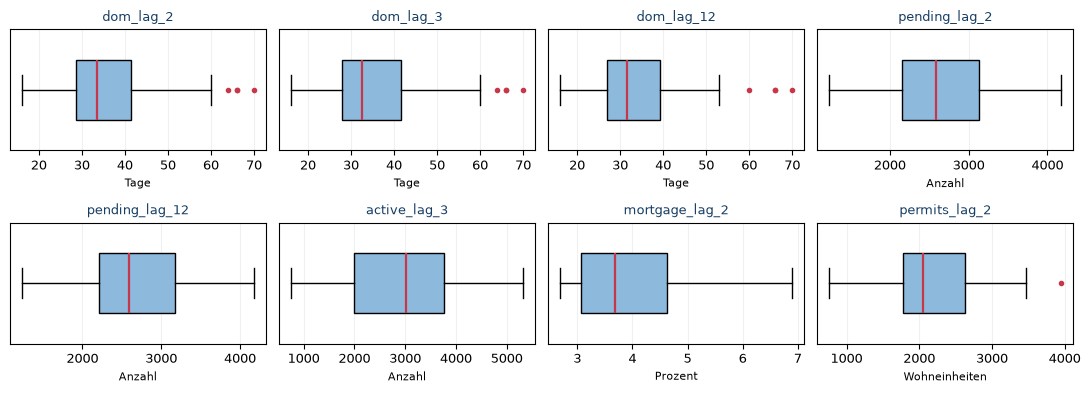

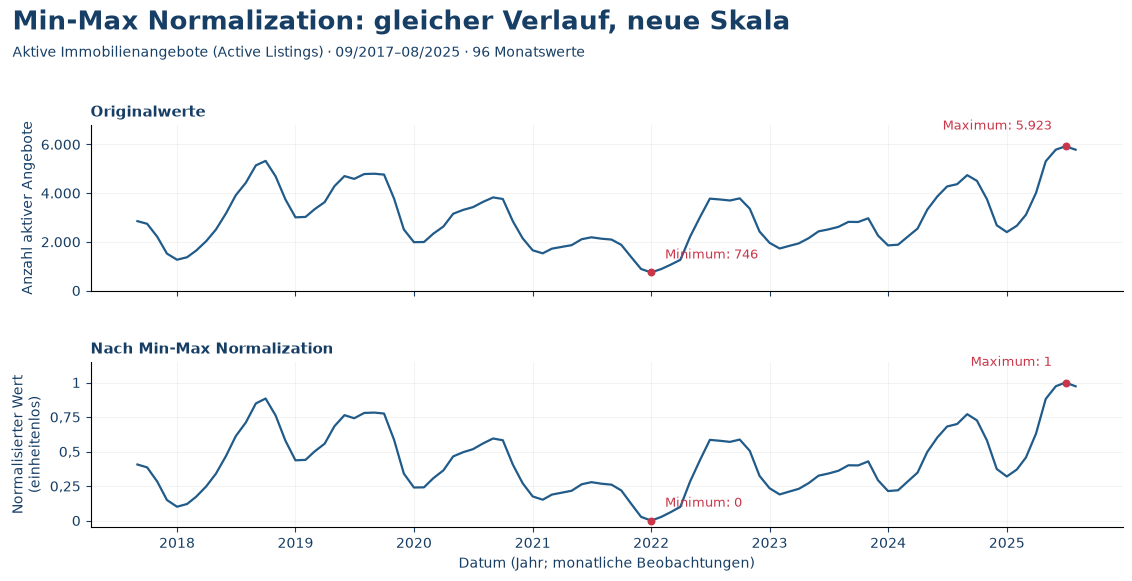

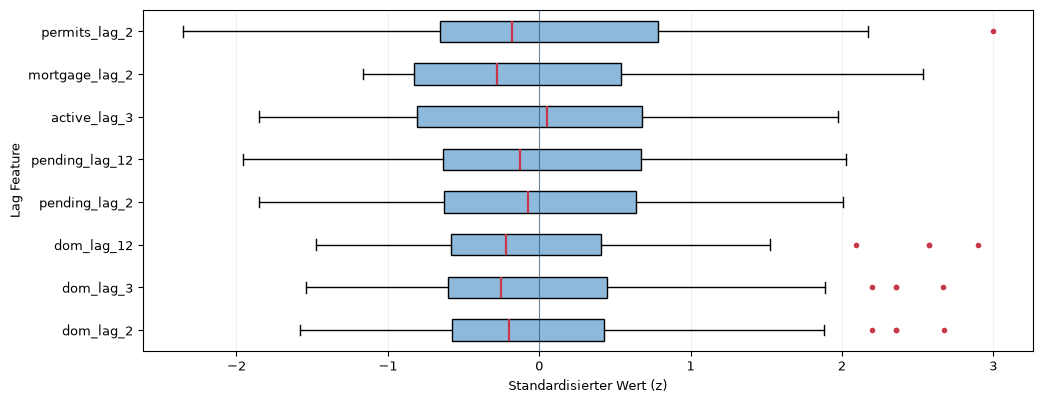

In [ ]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

plot_blue = "#173E65"
plot_red = "#C83749"
plot_fill = "#8CB9DC"
units = {"dom": "Tage", "pending": "Anzahl", "active": "Anzahl",
         "mortgage": "Prozent", "permits": "Wohneinheiten"}
box_style = {
    "orientation": "horizontal", "patch_artist": True,
    "medianprops": {"color": plot_red, "linewidth": 1.6},
    "flierprops": {"marker": ".", "markerfacecolor": plot_red,
                   "markeredgecolor": plot_red},
}

# Originaleinheiten: dieselben acht Trainingsmerkmale in zwei Zeilen.

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9}):
    fig, axes = plt.subplots(2, 4, figsize=(11, 4.0))
    for ax, feature in zip(axes.flat, LAG_COLUMNS):
        box = ax.boxplot(eda_unscaled[1][feature], widths=0.5, **box_style)
        box["boxes"][0].set_facecolor(plot_fill)
        ax.set_title(feature, fontsize=9, color=plot_blue)
        ax.set_yticks([])
        ax.grid(axis="x", alpha=0.18)
        ax.set_xlabel(units[feature.split("_lag_")[0]], fontsize=8)
    fig.tight_layout()
    plt.show()

# Unverändertes historisches Min-Max-Beispiel (keine Modellskalierung).

active_example = monthly_base.loc["2017-09":"2025-08", ["active"]]
assert len(active_example) == 96
minmax = MinMaxScaler().fit(active_example)
active_normalized = minmax.transform(active_example).ravel()
np.testing.assert_allclose([minmax.data_min_[0], minmax.data_max_[0]], [746, 5923])
active_dates = active_example.index.to_timestamp()
minimum_position = int(np.argmin(active_example["active"].to_numpy()))
maximum_position = int(np.argmax(active_example["active"].to_numpy()))

def german_number(value, position=None):
    return f"{value:,.2f}".rstrip("0").rstrip(".").replace(
        ",", "X"
    ).replace(".", ",").replace("X", ".")

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                     "text.color": plot_blue, "axes.labelcolor": plot_blue,
                     "xtick.color": plot_blue, "ytick.color": plot_blue}):
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.6), sharex=True)
    fig.subplots_adjust(left=0.10, right=0.96, top=0.80, bottom=0.19, hspace=0.43)
    fig.text(0.035, 0.975, "Min-Max Normalization: gleicher Verlauf, neue Skala",
             fontsize=19, weight="bold", va="top")
    fig.text(0.035, 0.92,
             "Aktive Immobilienangebote (Active Listings) · 09/2017–08/2025 · 96 Monatswerte",
             fontsize=10, va="top")
    for ax, values, title, ylabel in zip(
        axes, [active_example["active"].to_numpy(), active_normalized],
        ["Originalwerte", "Nach Min-Max Normalization"],
        ["Anzahl aktiver Angebote", "Normalisierter Wert\n(einheitenlos)"]
    ):
        ax.plot(active_dates, values, color="#215B89", linewidth=1.6)
        ax.set_title(title, loc="left", fontsize=11, fontweight="bold", color=plot_blue)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)
        ax.yaxis.set_major_formatter(FuncFormatter(german_number))
        for point_position, label, offset in [
            (minimum_position, "Minimum", (10, 10)),
            (maximum_position, "Maximum", (-10, 12)),
        ]:
            ax.scatter(active_dates[point_position], values[point_position],
                       color=plot_red, s=22, zorder=4)
            ax.annotate(f"{label}: {german_number(values[point_position])}",
                        (active_dates[point_position], values[point_position]),
                        xytext=offset, textcoords="offset points", color=plot_red,
                        fontsize=9, ha="left" if point_position == minimum_position else "right")
    axes[0].set_ylim(0, 6800)
    axes[1].set_ylim(-0.05, 1.15)
    axes[1].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axes[1].xaxis.set_major_locator(mdates.YearLocator())
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[1].set_xlabel("Datum (Jahr; monatliche Beobachtungen)")
    fig.text(0.035, 0.075,
             "Berechnung: (Wert − 746) / (5.923 − 746) · Minimum und Maximum aus dem Entwicklungszeitraum.",
             fontsize=9, color="#50667B")
    fig.text(0.035, 0.04,
             "Illustration der Methode: In der Validierung werden die Parameter jeweils ausschließlich im Training bestimmt.",
             fontsize=9, color="#50667B")
    plt.show()

# Z-Werte: bereits berechnete Standardisierung unverändert darstellen.
with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9}):
    fig, ax = plt.subplots(figsize=(10.5, 4.1))
    box = ax.boxplot([eda_scaled[1][feature] for feature in LAG_COLUMNS],
                     tick_labels=LAG_COLUMNS, **box_style)
    for patch in box["boxes"]:
        patch.set_facecolor(plot_fill)
    ax.axvline(0, color=plot_blue, linewidth=0.8, alpha=0.6)
    ax.set_xlabel("Standardisierter Wert (z)")
    ax.set_ylabel("Lag Feature")
    ax.grid(axis="x", alpha=0.18)
    fig.tight_layout()
    plt.show()



## 7. Aufbereitete Daten prüfen und speichern

Die vorbereiteten Tabellen und die zugehörigen Kontrollinformationen werden gespeichert. Dazu gehören die monatliche Datenbasis, die Feature- und Zielwerttabellen für die einzelnen Prognosehorizonte sowie die für die EDA aufbereiteten Trainingsdaten.

Die gespeicherten Einstellungen und Skalierungsparameter machen die Verarbeitung nachvollziehbar. Die Dateien können anschließend für EDA und Modellierung eingelesen werden. In der späteren zeitlichen Modellbewertung müssen Skalierungsparameter jeweils neu aus dem betreffenden Trainingsfenster bestimmt werden.

In [11]:
dictionary_rows = []
for name, lags in LAGS.items():
    for lag in lags:
        dictionary_rows.append({"feature": f"{name}_lag_{lag}", "source": name,
                                "measurement_month": f"t-{lag}",
                                "release_delay_assumed": RELEASE_DELAY[name],
                                "transformation": "Z-Standardisierung nur mit Trainingsdaten"})
for feature in ("month_sin", "month_cos"):
    dictionary_rows.append({"feature": feature, "source": "Kalender",
                            "measurement_month": "t+h", "release_delay_assumed": 0,
                            "transformation": "Zyklisch, keine weitere Skalierung"})
feature_dictionary = pd.DataFrame(dictionary_rows)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
monthly_base.to_csv(OUTPUT_DIR / "monthly_base.csv", index_label="month")
for horizon in range(1, 13):
    supervised_tables[horizon].to_csv(OUTPUT_DIR / f"supervised_h{horizon:02d}_unscaled.csv", index=False)
    eda_unscaled[horizon].to_csv(OUTPUT_DIR / f"eda_train_h{horizon:02d}_unscaled.csv", index=False)
    eda_scaled[horizon].to_csv(OUTPUT_DIR / f"eda_train_h{horizon:02d}_scaled.csv", index=False)
    eda_parameters[horizon].to_csv(OUTPUT_DIR / f"eda_scaler_h{horizon:02d}.csv", index=False)
feature_dictionary.to_csv(OUTPUT_DIR / "feature_dictionary.csv", index=False)
window_plan.to_csv(OUTPUT_DIR / "validation_windows.csv", index=False)
case_counts.to_csv(OUTPUT_DIR / "case_counts.csv")
quality_report.to_csv(OUTPUT_DIR / "raw_quality_report.csv")
protocol = {"source_document": "House_Demand_Forecasting_Data_Prep_EDA_Praezisiert.docx, Teil A, 29.10.2026",
            "eda_cutoff": str(EDA_CUTOFF), "validation_origins": VALIDATION_ORIGINS.astype(str).tolist(),
            "test_origin": str(TEST_ORIGIN), "release_delay_assumed": RELEASE_DELAY,
            "target_delay_assumed": TARGET_DELAY, "features": FEATURE_COLUMNS,
            "targets": TARGET_COLUMNS, "historical_vintages_verified": False}
(OUTPUT_DIR / "preparation_protocol.json").write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")

827